## Lab 4: Kernel PCA

In Lab 2 we saw that PCA, being a linear projection, cannot separate data whose classes are not linearly separable. Kernel PCA performs PCA in an implicit feature space defined by a kernel, allowing nonlinear structure to be captured.

You can use external libraries for linear algebra operations (e.g. `numpy.linalg`) but you are expected to write your own algorithms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigsh
from scipy.spatial.distance import cdist

np.random.seed(42)

# Exercise 1
Use `kPCA_data_2024.txt` and `kPCA_labels_2024.txt` in the `Datasets` folder. The first file contains the variables describing the data, the second one the labels of the classes.

### Load and explore the data

In [2]:
X = np.genfromtxt("../Datasets/kPCA_data_2024.txt")
y = np.genfromtxt("../Datasets/kPCA_labels_2024.txt")

print("X shape:", X.shape)
print("classes and counts:", dict(zip(*np.unique(y, return_counts=True))))

X shape: (6632, 20)
classes and counts: {np.float64(0.0): np.int64(5062), np.float64(1.0): np.int64(1570)}


The data lives in $D=20$ dimensions, with $n=6632$ points and two classes (imbalanced, roughly 76% / 24%). Let us plot the first two original dimensions and the per-feature statistics.

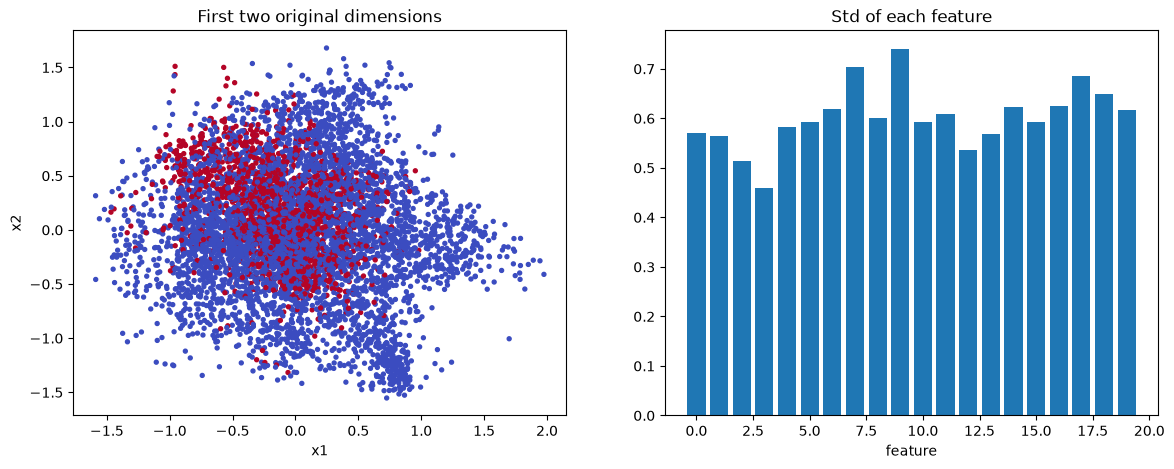

mean of features (max abs): 1.7815965831684603e-17


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X[:, 0], X[:, 1], c=y, s=8, cmap="coolwarm")
ax[0].set_title("First two original dimensions")
ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2")
ax[1].bar(range(X.shape[1]), X.std(axis=0))
ax[1].set_title("Std of each feature")
ax[1].set_xlabel("feature")
plt.show()
print("mean of features (max abs):", np.abs(X.mean(axis=0)).max())

In the first two raw dimensions the two classes are completely mixed. The features are already (almost) centred with comparable scales, but we standardize each feature to be safe.

In [4]:
X = (X - X.mean(axis=0)) / X.std(axis=0)

### Own PCA
Eigen-decomposition of the covariance matrix $C=\frac{1}{n}X^TX$.

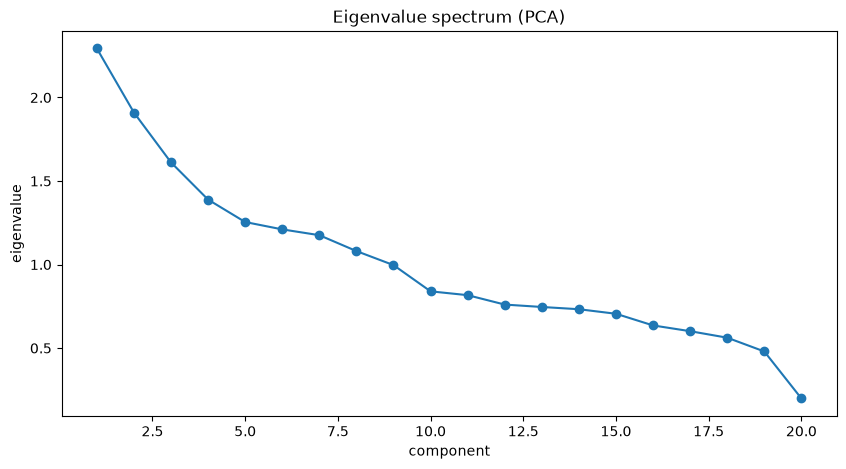

cumulative explained variance (first 5): [0.115 0.21  0.291 0.36  0.423]


In [5]:
def my_pca(X):
    """PCA via eigh on the covariance matrix. X must be centred. Returns eigenvalues (desc.), eigenvectors (columns)."""
    C = X.T @ X / X.shape[0]
    w, V = np.linalg.eigh(C)
    idx = np.argsort(w)[::-1]
    return w[idx], V[:, idx]

eigvals, eigvecs = my_pca(X)
X_pca = X @ eigvecs

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(eigvals) + 1), eigvals, "o-")
plt.title("Eigenvalue spectrum (PCA)")
plt.xlabel("component"); plt.ylabel("eigenvalue")
plt.show()
print("cumulative explained variance (first 5):", np.round(np.cumsum(eigvals)[:5] / eigvals.sum(), 3))

The spectrum decays slowly, with no clear gap: the structure is not captured by a few linear directions. Projection on the first two PCs:

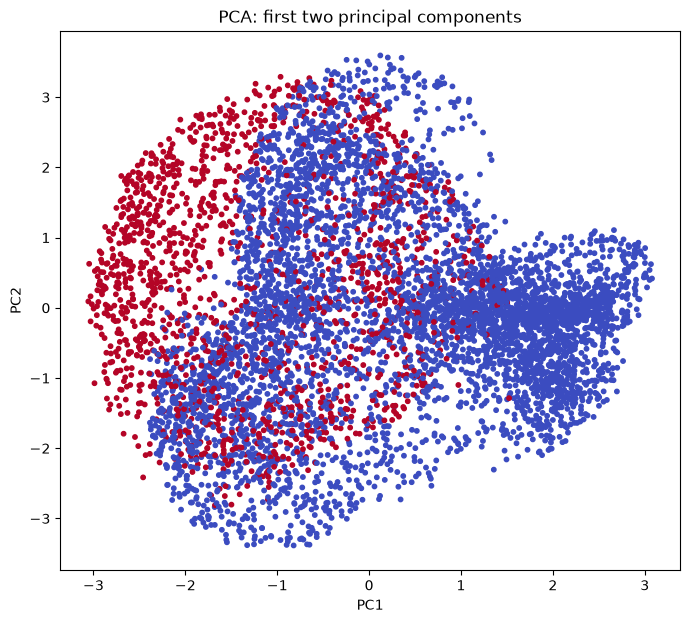

In [6]:
plt.figure(figsize=(8, 7))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=10, cmap="coolwarm")
plt.title("PCA: first two principal components")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

The classes overlap heavily: PCA, being linear, does not separate them.

### Own Kernel PCA

Given a kernel $k(x,x')$, build the Gram matrix $K_{ij}=k(x_i,x_j)$ and centre it in feature space:
$$\tilde K = K - \mathbf 1_n K - K\mathbf 1_n + \mathbf 1_n K\mathbf 1_n,\qquad (\mathbf 1_n)_{ij}=1/n .$$
Take the eigenpairs $(\lambda_j, v_j)$ of $\tilde K$. The projection of the training points on the $j$-th kernel principal component is $\sqrt{\lambda_j}\,v_j$ (equivalently, $\tilde K v_j/\sqrt{\lambda_j}$ with $v_j$ unit norm).

Kernels:
- Gaussian: $k(x,x')=\exp\!\left(-\frac{\|x-x'\|^2}{2\sigma^2}\right)$
- Polynomial (second version): $k(x,x')=(1+x^Tx')^\delta$

In [7]:
def gaussian_kernel(X, sigma):
    return np.exp(-cdist(X, X, "sqeuclidean") / (2 * sigma**2))

def poly_kernel(X, delta):
    return (1 + X @ X.T) ** delta

def center_kernel(K):
    # same as K - 1_n K - K 1_n + 1_n K 1_n, but using row/column means (O(n^2) instead of O(n^3))
    row = K.mean(axis=0, keepdims=True)
    col = K.mean(axis=1, keepdims=True)
    return K - row - col + K.mean()

def my_kpca(K, n_components=3):
    """Kernel PCA from a Gram matrix K. Returns projections (n x n_components) and eigenvalues."""
    n = K.shape[0]
    Kc = center_kernel(K)
    # only the top eigenpairs are needed (Lanczos iterations: much faster than the full decomposition)
    w, V = eigsh(Kc, k=n_components, which="LA")
    idx = np.argsort(w)[::-1]
    w, V = w[idx], V[:, idx]
    return V * np.sqrt(np.maximum(w, 0)), w

**Sanity check** against `sklearn` (components are defined up to a sign).

In [8]:
from sklearn.decomposition import KernelPCA

Z, _ = my_kpca(gaussian_kernel(X, 1.0), 3)
Z_sk = KernelPCA(n_components=3, kernel="rbf", gamma=1 / (2 * 1.0**2)).fit_transform(X)
print("Gaussian, sigma=1 | max abs diff (up to sign):",
      [float(np.min([np.abs(Z[:, j] - s * Z_sk[:, j]).max() for s in (1, -1)])) for j in range(3)])

Z, _ = my_kpca(poly_kernel(X, 3), 3)
Z_sk = KernelPCA(n_components=3, kernel="poly", degree=3, gamma=1, coef0=1).fit_transform(X)
print("Poly, delta=3     | max abs diff (up to sign):",
      [float(np.min([np.abs(Z[:, j] - s * Z_sk[:, j]).max() for s in (1, -1)])) for j in range(3)])

Gaussian, sigma=1 | max abs diff (up to sign): [1.6653345369377348e-15, 3.2751579226442118e-15, 3.4416913763379853e-15]
Poly, delta=3     | max abs diff (up to sign): [1.8474111129762605e-13, 2.717825964282383e-13, 6.750155989720952e-13]


### Gaussian kernel, $\sigma\in[0.05,2.0]$

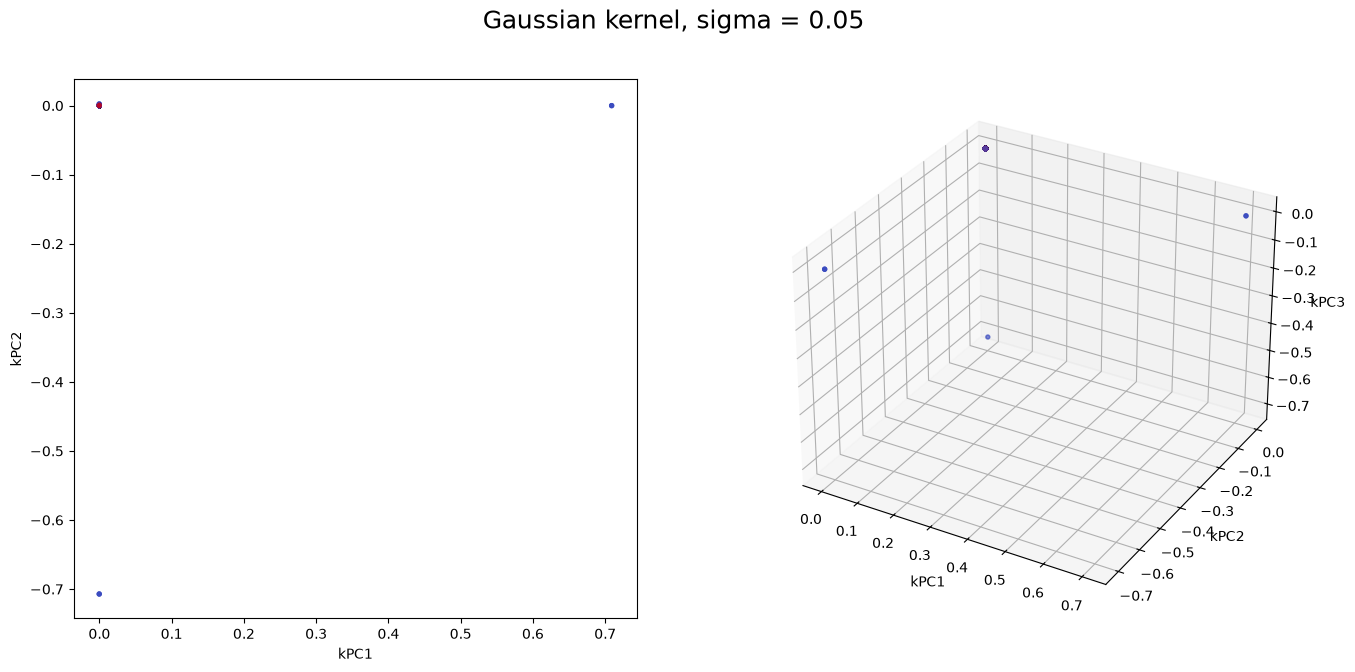

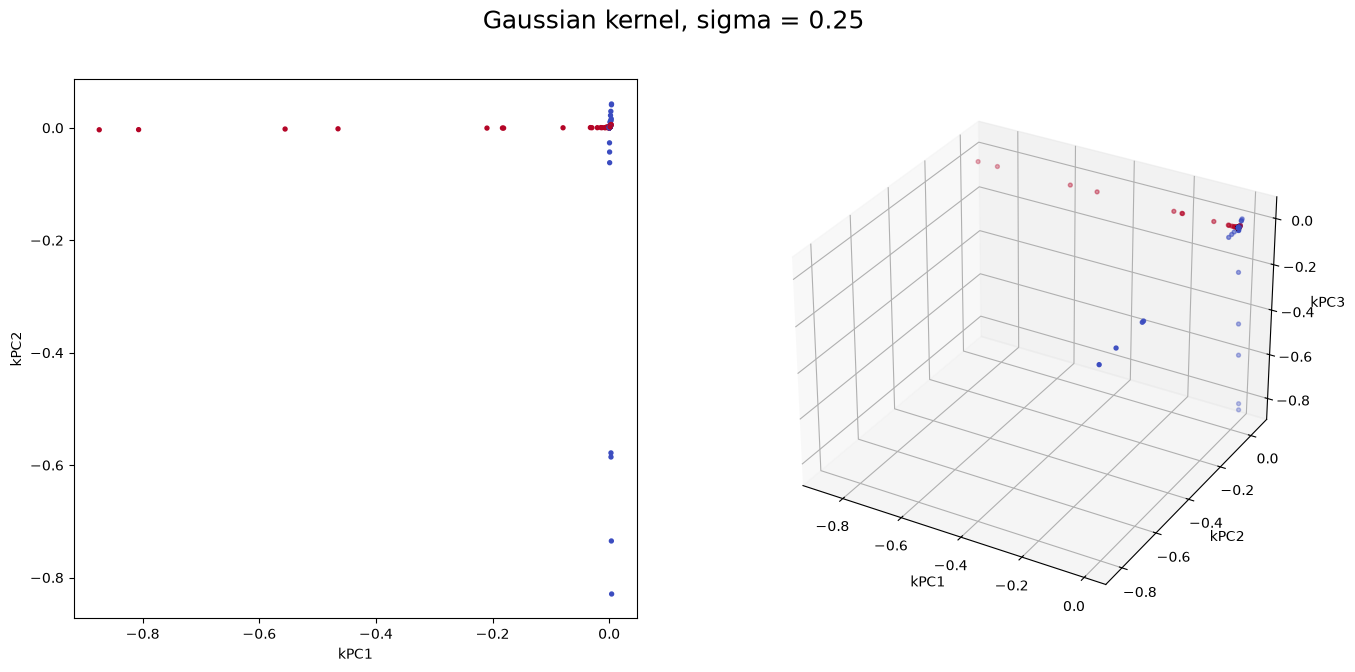

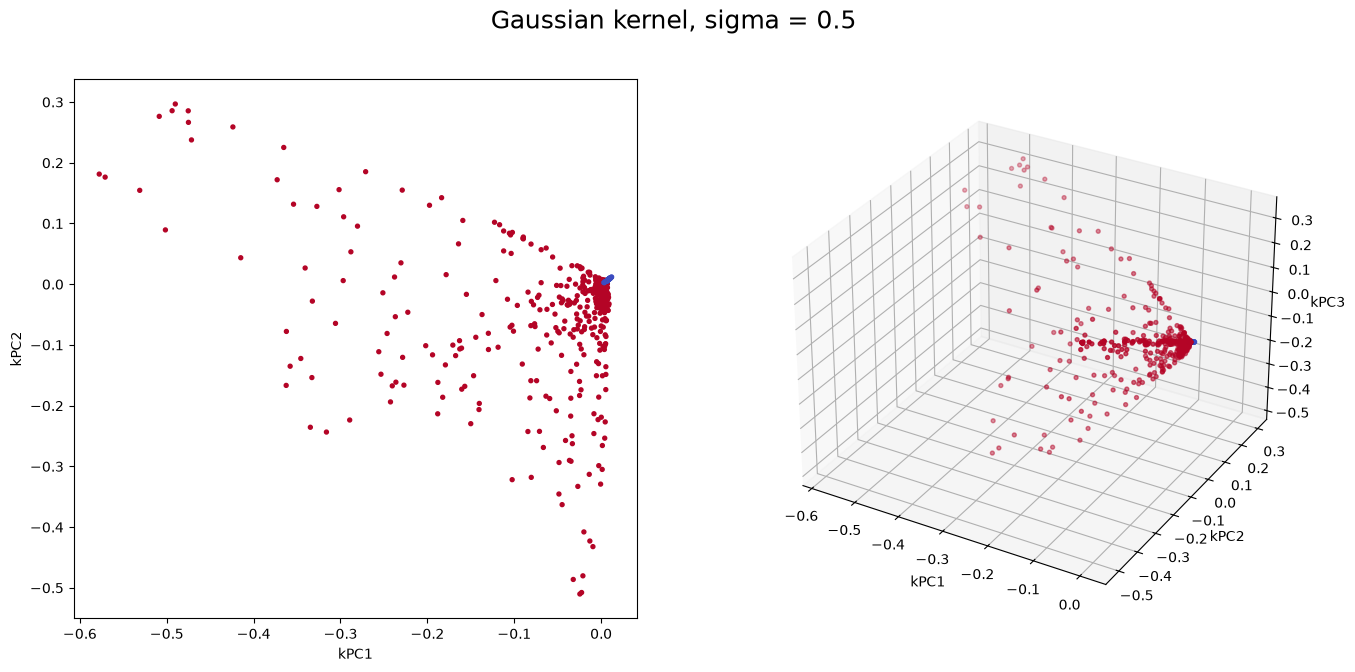

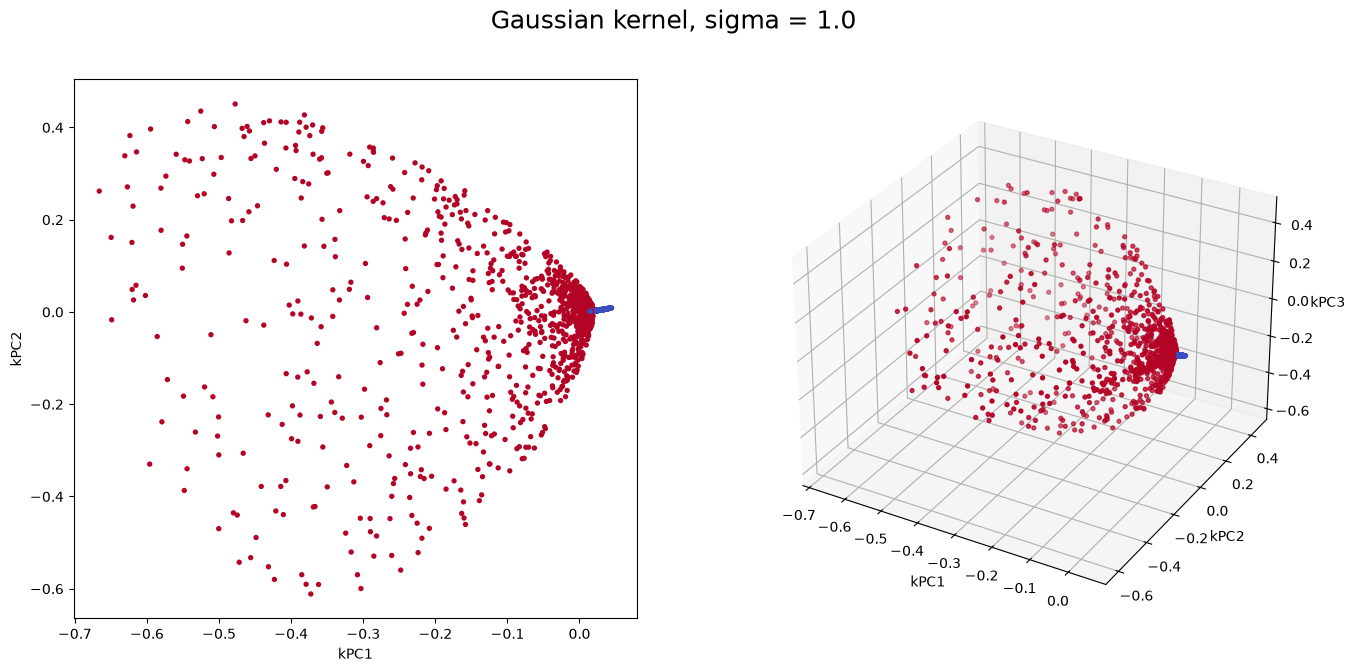

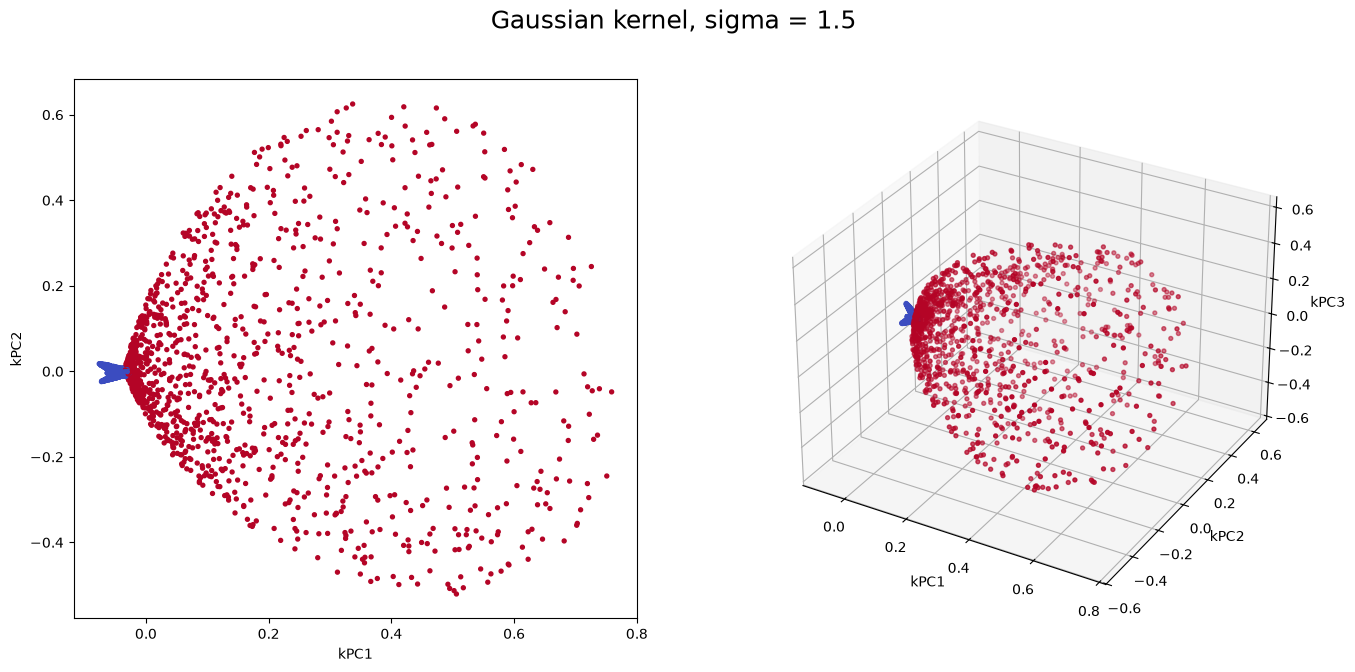

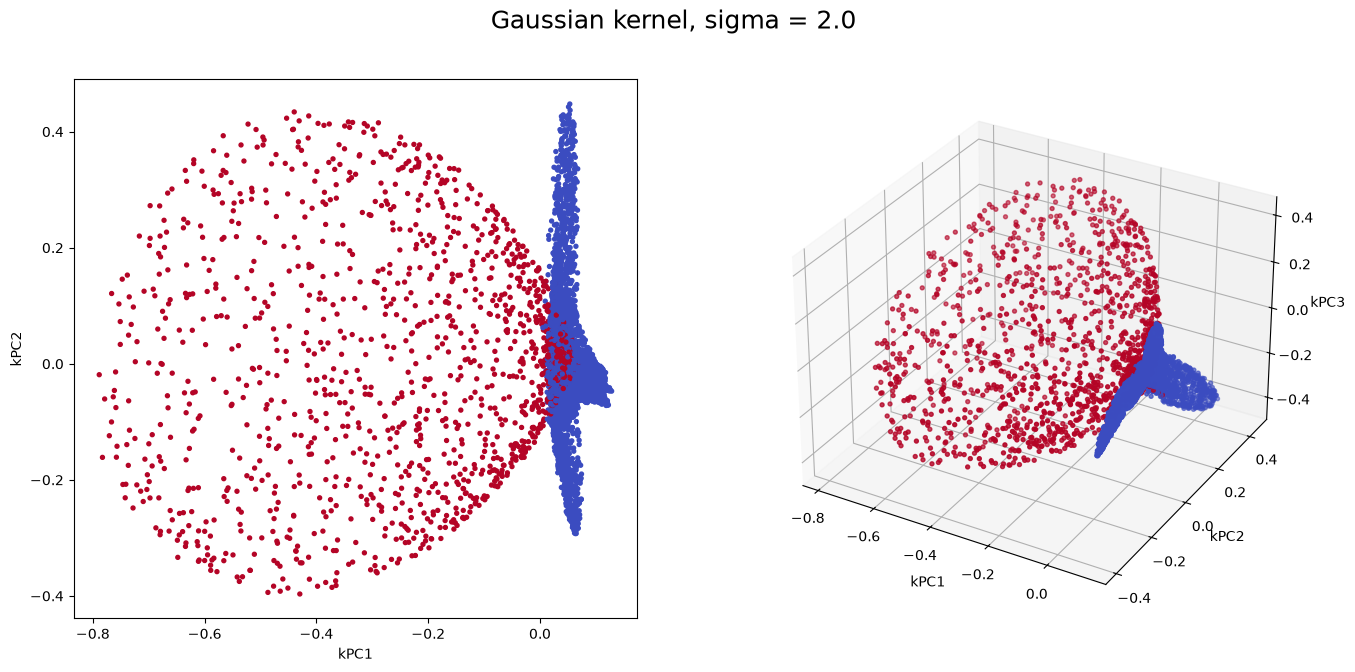

In [9]:
def plot_kpca(Z, title):
    fig = plt.figure(figsize=(16, 7))
    fig.suptitle(title, fontsize=18)
    ax = fig.add_subplot(1, 2, 1)
    ax.scatter(Z[:, 0], Z[:, 1], c=y, s=8, cmap="coolwarm")
    ax.set_xlabel("kPC1"); ax.set_ylabel("kPC2")
    ax = fig.add_subplot(1, 2, 2, projection="3d")
    ax.scatter3D(Z[:, 0], Z[:, 1], Z[:, 2], c=y, s=8, cmap="coolwarm")
    ax.set_xlabel("kPC1"); ax.set_ylabel("kPC2"); ax.set_zlabel("kPC3")
    plt.show()

for sigma in (0.05, 0.25, 0.5, 1.0, 1.5, 2.0):
    Z, w = my_kpca(gaussian_kernel(X, sigma), 3)
    plot_kpca(Z, f"Gaussian kernel, sigma = {sigma}")

### Polynomial kernel, varying $\delta$

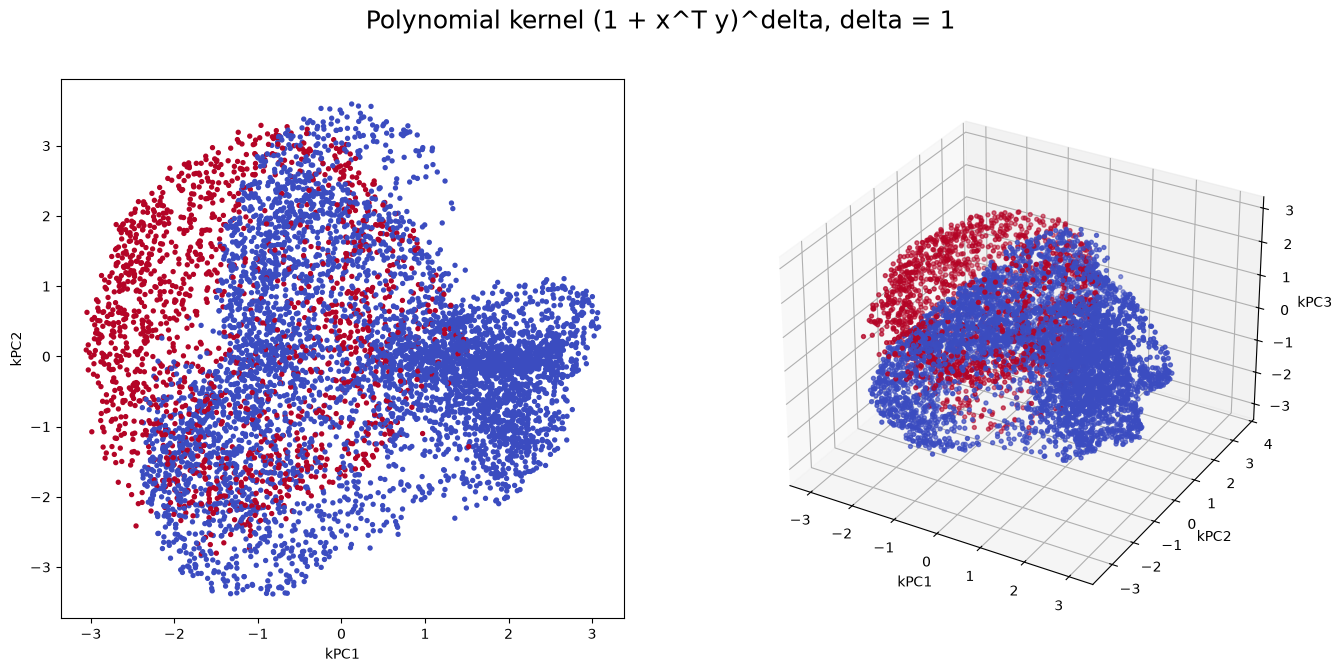

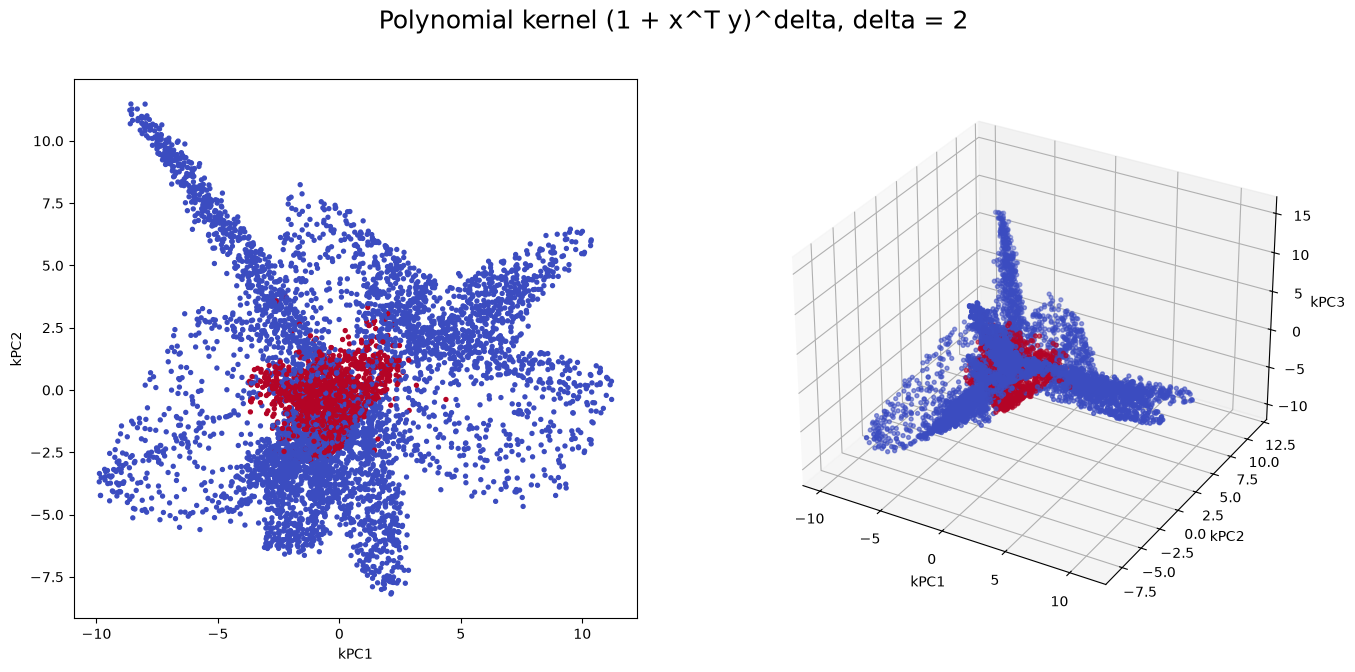

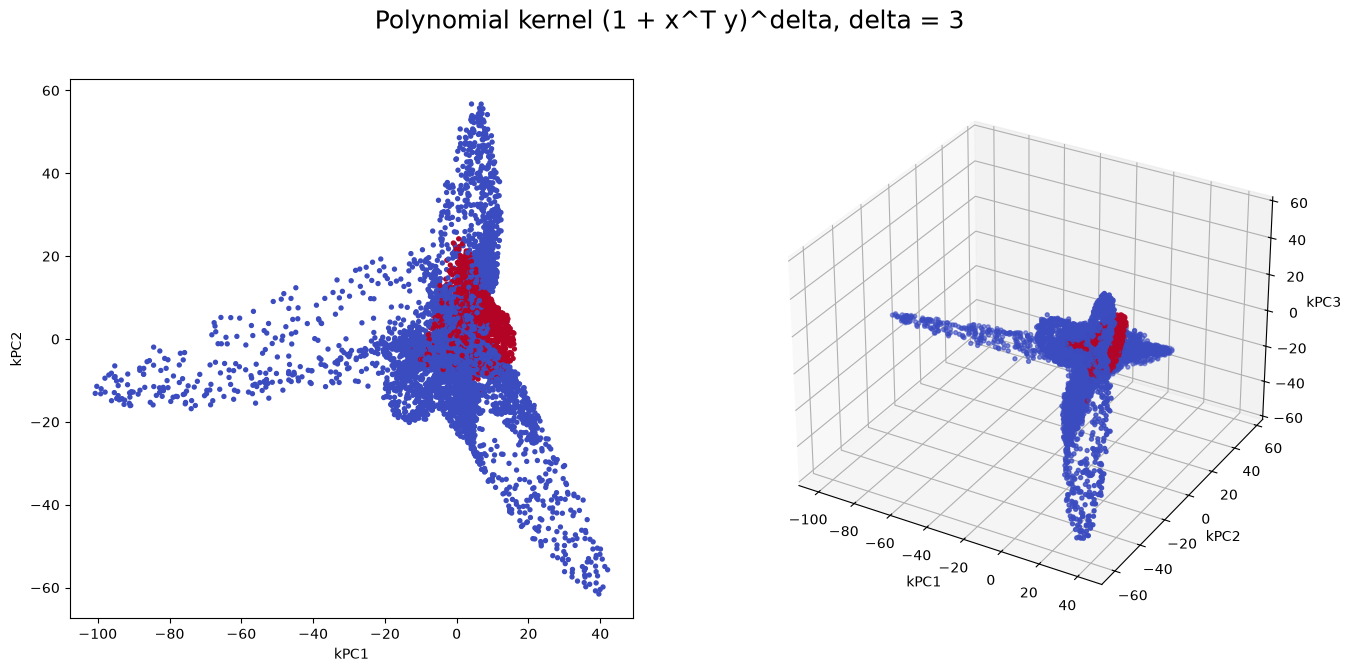

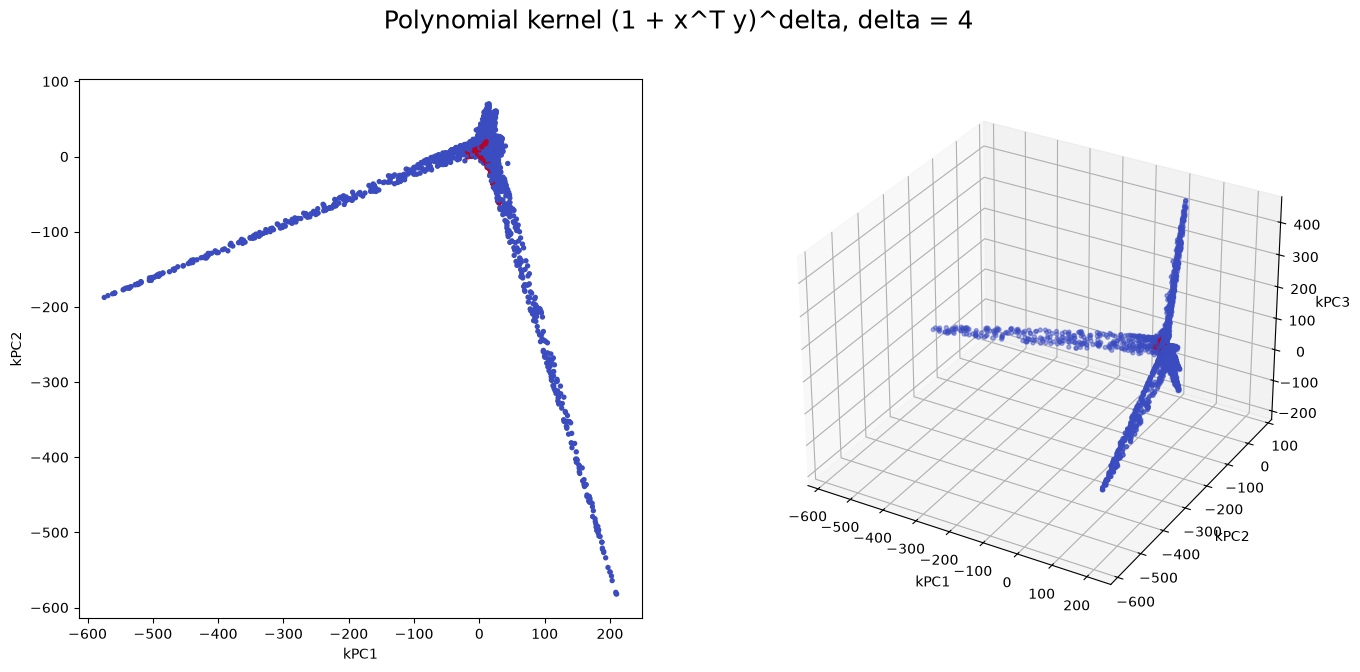

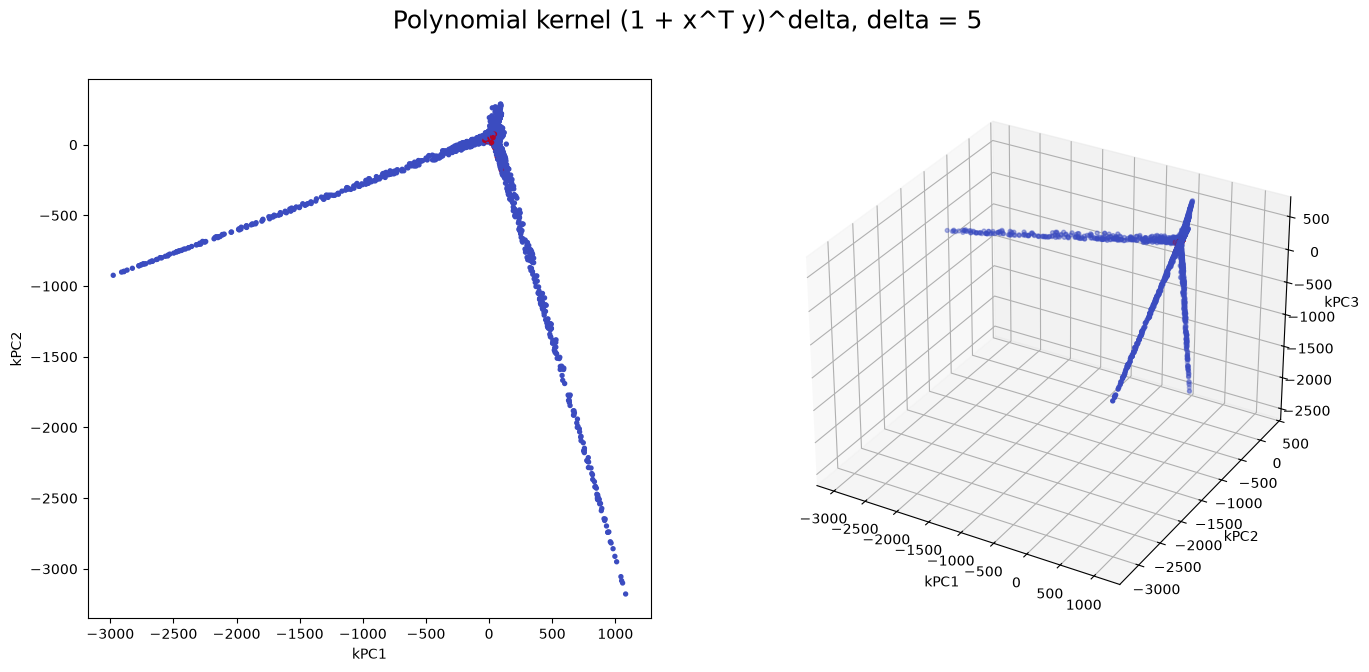

In [10]:
for delta in (1, 2, 3, 4, 5):
    Z, w = my_kpca(poly_kernel(X, delta), 3)
    plot_kpca(Z, f"Polynomial kernel (1 + x^T y)^delta, delta = {delta}")

### Comments
- **PCA / $\delta=1$**: the polynomial kernel with $\delta=1$ is exactly linear PCA (same projection up to sign). One class (red, class 1) sits on the left, but the two classes overlap a lot.
- **Polynomial kernel**: for $\delta\ge 2$ the data open up into a few "arms" (one per leading direction of the higher-order feature space). One class (red) stays in a compact blob at the centre, while the other (blue) spreads along the arms: the classes are separated *radially*, not by a hyperplane. For large $\delta$ the largest eigenvalues are dominated by a few outlying points, the scale explodes (see axes) and the central blob gets squeezed, so very high degrees are not useful.
- **Gaussian kernel**: $\sigma$ controls the locality. For very small $\sigma$ ($0.05$, $0.25$) the Gram matrix is close to the identity (each point is similar only to itself) and the projection carries no structure: the first components are determined by a few isolated points. For $\sigma\gtrsim 1$ a clear structure emerges: one class is compressed in a compact region while the other spreads out around it, and the separation improves as $\sigma$ grows towards $2$.

### Bonus
Quantify the separation: accuracy of a logistic regression on the first 3 kernel PCs, as a function of $\sigma$ and $\delta$. Note that the logistic regression is a *linear* classifier: when a class sits in the middle and the other around it (polynomial $\delta\ge2$) it cannot do better than the majority-class baseline, even though the plots show a clear radial structure.

majority-class baseline: 0.763
PCA (3 PCs): 0.87


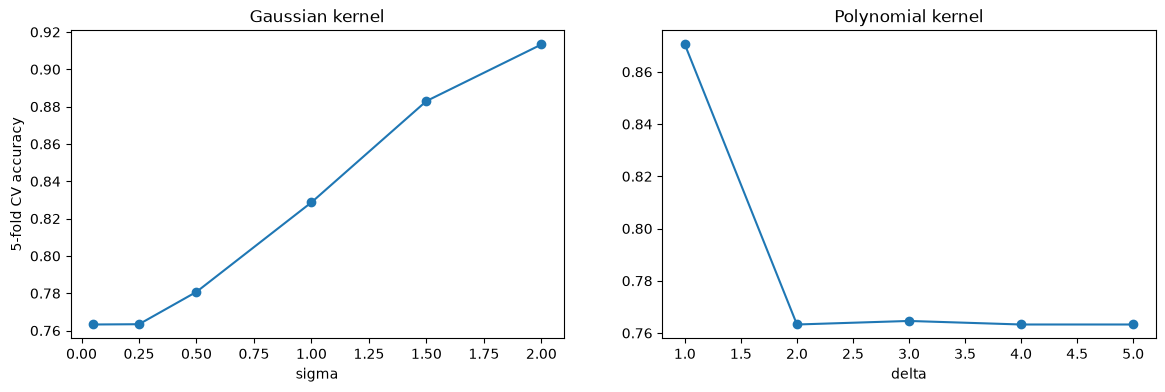

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

def score(Z):
    return cross_val_score(LogisticRegression(max_iter=1000), Z, y, cv=5).mean()

sigmas = [0.05, 0.25, 0.5, 1.0, 1.5, 2.0]
deltas = [1, 2, 3, 4, 5]
acc_g = [score(my_kpca(gaussian_kernel(X, s), 3)[0]) for s in sigmas]
acc_p = [score(my_kpca(poly_kernel(X, d), 3)[0]) for d in deltas]
print("majority-class baseline:", round(max(np.mean(y == 0), np.mean(y == 1)), 3))
print("PCA (3 PCs):", round(score(X_pca[:, :3]), 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(sigmas, acc_g, "o-"); ax[0].set_title("Gaussian kernel"); ax[0].set_xlabel("sigma"); ax[0].set_ylabel("5-fold CV accuracy")
ax[1].plot(deltas, acc_p, "o-"); ax[1].set_title("Polynomial kernel"); ax[1].set_xlabel("delta")
plt.show()